## SFR density at different redshifts

The idea is to replicate Fig.10 from Hill et al. (2020). 



In [2]:
import os
import h5py
import numpy as np
import matplotlib.pyplot as plt
from astropy.cosmology import FlatLambdaCDM
from set_style import set_style
from scipy.stats import binned_statistic

caesar_path = '/data20/TheThreeHundred/data_NewICs/catalogues/Caesar/GIZMO_7k/NewMDCLUSTER_0129/'

h = 0.678

with h5py.File('HaloID_track_Gizmo7k.hdf5','r') as f:
    z = f['z'][()]

a_t = 1./(1+z)
cosmo = FlatLambdaCDM(H0=67.8, Om0=0.31)
lookback_time = cosmo.lookback_time(z).value

In [3]:
def get_sfr_density(clusid, snap, mcut=1e11, n_views=50, random=True, proj='xy'):

    # read properties

    pos,_, sfr, index_gal, haloID = read_properties(clusid, snap)
    
    mask = compute_mass_limit(clusid, snap, mcut, haloID) # keep halos with M>mcut 

    pos = pos - pos[index_gal]
    
    pos, sfr = pos[mask]*a_t[128-snap], sfr[mask] # pos in physical kpc

    rmax = 1800 # kpc, 10 Mpc^2
    nbins = 20

    rbins = np.logspace(np.log10(10), np.log10(rmax), 20)
    rbins = np.insert(rbins,0,0) # add central object
    
    # Random projection

    if random:

        # random projections
        theta, phi = random_los(n_views, seed=11)
        profiles = np.zeros((n_views, nbins))
    
        for i in range(n_views):
    
            x,y,z = project(pos, theta[i], phi[i])
    
            r_dist = np.hypot(x,y)
        
            sfr_sum, bin_edges, bin_index = binned_statistic(r_dist, sfr, statistic='sum', bins=rbins)
        
            cumulative_sfr = np.cumsum(sfr_sum)

            profiles[i] = cumulative_sfr

        p10, median_sfr, p90 = np.percentile(profiles, [10,50,90], axis=0)
        
        
        bin_edges_outer = bin_edges[1:]
        area_Mpc = np.pi*np.power(bin_edges_outer,2)/1e6
    
        return p10, median_sfr, p90, area_Mpc

    else:
        
        if proj == 'xy':
            r_dist = np.linalg.norm(pos[:,[0,1]], axis=1)
        elif proj == 'xz':
            r_dist = np.linalg.norm(pos[:,[0,2]], axis=1)
        elif proj == 'yz':
            r_dist = np.linalg.norm(pos[:,[1,2]], axis=1)
        
        sfr_sum, bin_edges, bin_index = binned_statistic(r_dist, sfr, statistic='sum', bins=rbins)
        
        cumulative_sfr = np.cumsum(sfr_sum)
        bin_edges_outer = bin_edges[1:]
        
        area_Mpc = np.pi*np.power(bin_edges_outer,2)/1e6
        
        return cumulative_sfr, area_Mpc



def read_properties(clusid, snap):

    with h5py.File('HaloID_track_Gizmo7k.hdf5','r') as f:
        main_haloID = f[f'cluster_{clusid:04d}/id_list'][()]

    central_ID = main_haloID[128-snap] #reverse order

    try:

        # identify index for central galaxy properties
        with h5py.File(caesar_path+f'Caesar_C200_snap_{snap:03d}.hdf5','r') as f:
            HaloID = f['halo_data/AHF_haloID'][()]
            parent_halo = f['galaxy_data/parent_halo_index'][()]
            central = f['galaxy_data/central'][()]
            pos = f['galaxy_data/pos'][()] # ckpc
            stellar_mass = f['galaxy_data/dicts/masses.stellar'][()] # msun
            sfr = f['galaxy_data/sfr'][()] # msun/yr    
        
    
        index_halo = np.argwhere(HaloID == central_ID)
        index_gal = np.argwhere((parent_halo == index_halo)&(central == True))[0][0]


    except:
        print(f'failed at snapshot {snap}')
        return 0,0,0,0
        
    return pos, stellar_mass, sfr, index_gal, HaloID[parent_halo]


def compute_mass_limit(clusid, snap, mcut, haloID):
    path = '/data20/TheThreeHundred/data_NewICs/catalogues/AHF/GIZMO_7k_R200c/'
    
    listdir = [x for x in os.listdir(path+f'NewMDCLUSTER_{clusid:04d}/') if x.endswith('_halos')]
    listdir.sort()  
    fname = path+f'NewMDCLUSTER_{clusid:04d}/'+listdir[snap]
    cols = [0,3]
    ID, Mh = np.genfromtxt(fname, usecols=cols, skip_header=1, unpack=True, dtype=None) # all

    ID = ID[Mh/0.678>mcut]
    mask = np.isin(haloID, ID)

    return mask

In [4]:
# to calculate random projections

def projection_basis(theta, phi):
    """Orthonormal basis (e1, e2, n) for a LOS given polar angle theta and azimuth phi [rad]."""
    st, ct = np.sin(theta), np.cos(theta)
    sp, cp = np.sin(phi), np.cos(phi)
    n = np.array([st * cp, st * sp, ct])     # line of sight
    e1 = np.array([ct * cp, ct * sp, -st])   # d n / d theta  (unit)
    e2 = np.array([-sp, cp, 0.0])            # d n / d phi    (unit)
    return e1, e2, n
 
 
def project(pos, theta, phi):
    """
    Rotate positions into the frame of a given LOS.
 
    pos    : (N, 3) array of X, Y, Z. Relative positions already
    Returns x_sky, y_sky (sky-plane coords) and z_los (depth along LOS),
    all centred on the central object, same units as the input.
    """
    e1, e2, n = projection_basis(theta, phi)
    d = pos
    # If the box is periodic and the object sits near an edge, wrap d first:
    # d = (d + 0.5 * L) % L - 0.5 * L
    R = np.vstack([e1, e2, n])               # (3, 3) rotation matrix, rows = new axes
    xyz = d @ R.T
    return xyz[:, 0], xyz[:, 1], xyz[:, 2]
 
 
def random_los(n_views, seed=None):
    """
    Isotropic LOS directions: phi uniform in [0, 2pi), cos(theta) uniform in [-1, 1].
    (Drawing theta uniformly would over-sample the poles.)
    """
    rng = np.random.default_rng(seed)
    phi = rng.uniform(0.0, 2.0 * np.pi, n_views)
    theta = np.arccos(rng.uniform(-1.0, 1.0, n_views))
    return theta, phi



In [28]:
p10, median_sfr, p90 , area = get_sfr_density(129, 55, mcut=1e10, proj=True)

In [31]:
median_sfr

array([ 3200.02690715,  3323.6759807 ,  3324.37041372,  3331.7844343 ,
        3345.79657117,  3366.32735956,  3405.49066596,  3496.72608325,
        3582.2981737 ,  3754.84784973,  3973.91716722,  4077.02851901,
        4193.4143183 ,  4435.82078773,  4845.45619901,  5441.92104902,
        6186.62057363,  7096.92249256,  8443.70285984, 10087.23140376])

## Plot


In [54]:
sfr_density_z5, surface_z5 = get_sfr_density(129, 47, mcut=1e11, proj='xz')
sfr_density_z4, surface_z4 = get_sfr_density(129, 55, mcut=1e11, proj='xz')

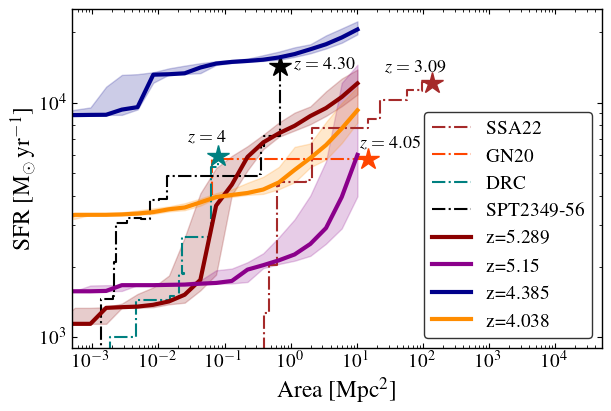

In [41]:




# -----------------------------------------------------------------
# . Load digitized data
# -----------------------------------------------------------------
csv_files = {
    #"Miller2018":    "obs/miller.csv",
    "SSA22_cluster": "obs/ssa22.csv",
    "GN20":          "obs/gn20.csv",
    "DRC":           "obs/drc.csv",
    "SPT2349-56":    "obs/spt.csv",
}

data = {name: np.loadtxt(path, delimiter=",") for name, path in csv_files.items()}

# -----------------------------------------------------------------
# . Plot metadata: color, redshift label, whether to draw as a curve
#    or as a vertical reference line
# -----------------------------------------------------------------
meta = {
    "SPT2349-56":    dict(color="black",  lw=1.5, label_z="4.30", kind="curve"),
    "SSA22_cluster": dict(color="brown",    lw=1.5, label_z="3.09", kind="curve"),
    "GN20":          dict(color="orangered",lw=1.5, label_z="4.05", kind="curve"),
    "DRC":           dict(color="teal",     lw=1.5, label_z="4", kind="curve"),
    #"Miller2018":    dict(color="magenta",    lw=1.5, label_z=None, kind="vline"),
}

legend_names = {
    "SPT2349-56":    "SPT2349-56",
    "SSA22_cluster": "SSA22",
    "GN20":          "GN20",
    "DRC":           "DRC",
    #"Miller2018":    "Miller et al. 2018",
}

fs = 17

# -----------------------------------------------------------------
# . Reproduce the plot
# -----------------------------------------------------------------
set_style('mnras')
fig, ax = plt.subplots(figsize=(6, 4))

#ax.set_title('Cumulative star-formation rate', fontsize=fs+2)

for name, arr in data.items():
    m = meta[name]
    x, y = arr[:, 0], arr[:, 1]

    if m["kind"] == "vline":
        x_ref = np.mean(x)
        ax.plot(x,y, color=m["color"], linestyle=":", lw=m["lw"])
        #ax.text(5e-3, 1e4, "Miller+18", rotation=0, ha="left", va="top", fontsize=10)
        continue

    ax.step(x, y, where="post", color=m["color"], lw=m["lw"], ls='-.',
             label=legend_names[name])
    ax.plot(x[-1], y[-1], marker="*", markersize=16, color=m["color"])

    if m["label_z"] is not None:
        if name == "SSA22_cluster":
            ax.annotate(rf"$z = {m['label_z']}$", (20, y[-1]),
                    textcoords="offset points", xytext=(5, 8), fontsize=fs-4)
        elif name=='DRC':
            ax.annotate(rf"$z = {m['label_z']}$", (0.02, y[-1]+200),
                    textcoords="offset points", xytext=(6, 8), fontsize=fs-4)
        elif name=='SPT2349-56':
            ax.annotate(rf"$z = {m['label_z']}$", (0.8, 1.25e4),
                    textcoords="offset points", xytext=(6, 8), fontsize=fs-4)
        else:
            ax.annotate(rf"$z = {m['label_z']}$", (8, y[-1]),
                    textcoords="offset points", xytext=(6, 8), fontsize=fs-4)

'''
ax.scatter(1.5e-1, 1e3, marker="*", s=16**2, color='olive', label='AzTEC-3')
ax.annotate(r"$z = 5.3$", (1.5e-1, 1e3),
                    textcoords="offset points", xytext=(6, 8), fontsize=11)

ax.scatter(7e0, 9e2, marker="*", s=16**2, color='crimson', label='HDF850.1')
ax.annotate(r"$z = 5.18$", (7e0, 9e2),
                    textcoords="offset points", xytext=(6, 8), fontsize=11)
'''
### ADD SIMULATED DATA

#snap_list = [45,46,47, 52,55]
#colors = ['darkred', 'darkorange', 'darkgreen','darkblue', 'darkmagenta']
colors = ['darkred','darkmagenta' ,'darkblue', 'darkorange']
snap_list = [45,46, 52,55]
z_list = [z[128-snapi] for snapi in snap_list]


i=0
for snap,zi in zip(snap_list,z_list):
    
    p10, sfr_density, p90, surface = get_sfr_density(129, snap, mcut=1e11, n_views=200)

    ax.plot(surface, sfr_density, lw=3, ls='-', color=colors[i], label=f'z={zi}')
    ax.fill_between(surface, p10, p90, color=colors[i], alpha=0.2)
    i+=1


######
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlim(5e-4, 5e4)
ax.set_ylim(9e2, 2.5e4)
ax.set_xlabel(r"Area [Mpc$^2$]", fontsize=fs)
ax.set_ylabel(r"SFR [M$_\odot\,$yr$^{-1}$]", fontsize=fs)
#ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1), borderaxespad=0,
#          fontsize=fs-3, frameon=False)
ax.legend(loc="lower right", fontsize=fs-3, frameon=True)
ax.tick_params(which="both", direction="in", top=True, bottom=True, right=True, labelsize=fs-3)


#ax.legend(loc="upper left", fontsize=8, frameon=True)
#ax.tick_params(which="both", direction="in", top=True, right=True, labelsize=10)

#plt.tight_layout()
plt.savefig("plots/sfr_area_mpc_random200.png", dpi=200,bbox_inches="tight")
plt.show()